# Main-text figures

Each code cell is identical to the script named above it, which `make figures` runs to
write the PDF to `figures/`. The cells read the data in `data/generated/` (see the
README) and can be run in any order.

## Figure 1
`scripts/figures/lattice_schematic.py`

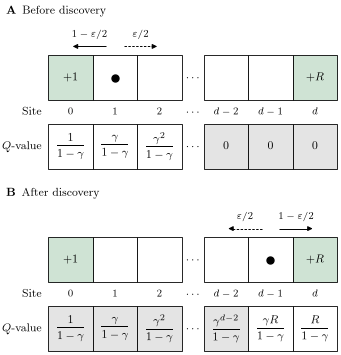

In [1]:
"""Figure 1: a lone agent's step probabilities and Q-values on the lattice, before and
after it discovers the distant reward R at site d.

Gray cells are Q-values not yet updated: never visited (A) or not visited since R was
found (B). The dashed arrow is the step against the greedy direction.
"""

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from competitive_exploration.plotting import save_figure, use_paper_style

use_paper_style()
plt.rcParams.update({"font.size": 8, "savefig.pad_inches": 0.02})
SMALL = 7

REWARD_FILL, STALE_FILL = "#cfe3d4", "#e4e4e4"
GAP = 0.55  # space between the environment and Q-value rows
SITES = ["0", "1", "2", None, "d-2", "d-1", "d"]
XS = [0, 1, 2, 2.75, 3.5, 4.5, 5.5]  # column centers; the ellipsis column is narrow
REWARDS = ["+1", "", "", None, "", "", "+R"]
X_LEFT = -1.45
F = r"\displaystyle\frac{%s}{1-\gamma}"

PANELS = [
    (
        "A",
        "Before discovery",
        1,
        (r"1-\varepsilon/2", r"\varepsilon/2"),
        [F % 1, F % r"\gamma", F % r"\gamma^2", None, "0", "0", "0"],
        [1, 1, 1, None, 0, 0, 0],
    ),
    (
        "B",
        "After discovery",
        5,
        (r"\varepsilon/2", r"1-\varepsilon/2"),
        [
            F % 1,
            F % r"\gamma",
            F % r"\gamma^2",
            None,
            F % r"\gamma^{d-2}",
            F % r"\gamma R",
            F % "R",
        ],
        [0, 0, 0, None, 0, 1, 1],
    ),
]


def draw_panel(ax, label, title, agent, probs, q, updated):
    y_env, y_site, y_q = 0.0, -GAP / 2, -1.0 - GAP
    for x, site, reward, q_value, is_updated in zip(XS, SITES, REWARDS, q, updated):
        if site is None:
            for y in (y_env + 0.5, y_site, y_q + 0.5):
                ax.text(x, y, r"$\cdots$", ha="center", va="center")
            continue
        ax.add_patch(
            Rectangle(
                (x - 0.5, y_env),
                1,
                1,
                edgecolor="black",
                linewidth=0.6,
                facecolor=REWARD_FILL if reward else "white",
            )
        )
        if reward:
            ax.text(x, y_env + 0.5, f"${reward}$", ha="center", va="center")
        ax.text(x, y_site, f"${site}$", ha="center", va="center", fontsize=SMALL)
        ax.add_patch(
            Rectangle(
                (x - 0.5, y_q),
                1,
                1,
                edgecolor="black",
                linewidth=0.6,
                facecolor="white" if is_updated else STALE_FILL,
            )
        )
        ax.text(x, y_q + 0.5, f"${q_value}$", ha="center", va="center")

    x_agent = XS[agent]
    ax.plot(x_agent, y_env + 0.5, "o", color="black", markersize=5)
    for dx, p in zip((-1, 1), probs):
        x0, x1, y = x_agent + 0.2 * dx, x_agent + 0.95 * dx, y_env + 1.2
        ax.plot(
            [x0, x1 - 0.08 * dx],
            [y, y],
            color="black",
            linewidth=0.7,
            linestyle="-" if p.startswith("1") else (0, (2.5, 1.5)),
            solid_capstyle="butt",
        )
        ax.annotate(
            "",
            xy=(x1, y),
            xytext=(x1 - 0.1 * dx, y),
            arrowprops={
                "arrowstyle": "-|>",
                "color": "black",
                "linewidth": 0.7,
                "mutation_scale": 7,
                "shrinkA": 0,
                "shrinkB": 0,
            },
        )
        ax.text(
            x_agent + 0.575 * dx,
            y_env + 1.47,
            f"${p}$",
            ha="center",
            va="center",
            fontsize=SMALL,
        )

    ax.text(-0.65, y_site, "Site", ha="right", va="center")
    ax.text(-0.65, y_q + 0.5, r"$Q$-value", ha="right", va="center")
    ax.text(X_LEFT, y_env + 2.0, rf"\textbf{{{label}}}\enspace {title}", va="center")
    ax.set_xlim(X_LEFT, XS[-1] + 0.55)
    ax.set_ylim(y_q - 0.05, y_env + 2.2)
    ax.set_aspect("equal")
    ax.axis("off")


fig, axes = plt.subplots(2, 1, figsize=(4.03, 3.75))
for ax, panel in zip(axes, PANELS):
    draw_panel(ax, *panel)
fig.tight_layout(h_pad=1.2)

save_figure(fig, "lattice_schematic.pdf")

## Figure 2
`scripts/figures/single_agent_optimal_exploration.py`

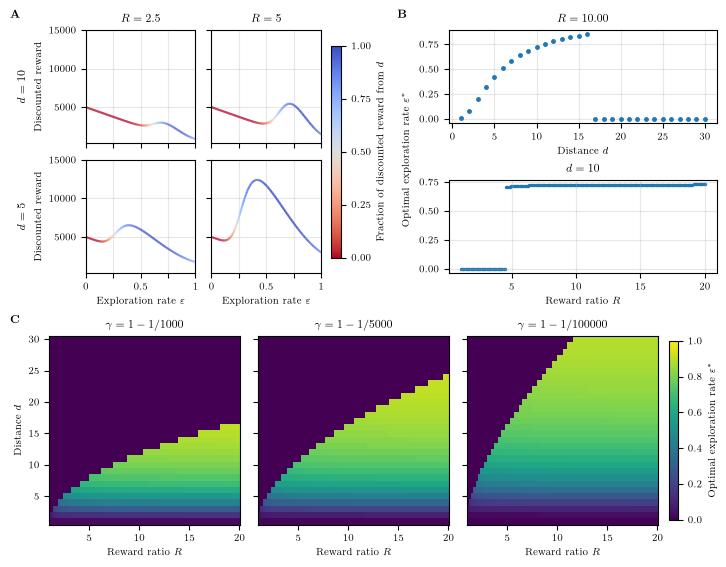

In [2]:
"""Figure 2: (A) a lone agent's discounted reward against its exploration
rate, (B) the optimal rate against distance and against reward ratio, and (C) the optimal
rate over reward ratio and distance for three discount factors."""

import matplotlib.pyplot as plt
import numpy as np

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    CM,
    PNAS_WIDTHS,
    add_colored_curve,
    add_row_label,
    centers_to_edges,
    save_figure,
    use_paper_style,
)

use_paper_style(final_size=True)
rewards_data = np.load(DATA_DIR / "single_agent_rewards.npz")
opt_data = np.load(DATA_DIR / "opt_eps_single.npz")

fig = plt.figure(figsize=(PNAS_WIDTHS["double"], 14 * CM), layout="constrained")
top, panel_c = fig.subfigures(2, 1, height_ratios=[1.22, 1])
panel_a, panel_b = top.subfigures(1, 2, width_ratios=[0.54, 0.46])

for subfig, letter in [(panel_a, "A"), (panel_b, "B"), (panel_c, "C")]:
    subfig.text(0, 1, rf"\textbf{{{letter}}}", ha="left", va="top", fontsize=8)

# A
rewards, eps_grid = rewards_data["rewards"], rewards_data["eps_grid"]
d_values, R_values = rewards_data["d_values"], rewards_data["R_values"]
total = rewards.sum(axis=-1)
pad = 0.05 * (total.max() - total.min())

axes = panel_a.subplots(len(d_values), len(R_values), sharex=True, sharey=True)
for a, d in enumerate(d_values):
    for r, R in enumerate(R_values):
        ax = axes[a, r]
        y = total[a, r]
        add_colored_curve(ax, eps_grid, y, rewards[a, r, :, 1] / y, linewidth=1.5)
        ax.set_xlim(0, 1)
        ax.set_ylim(total.min() - pad, total.max() + pad)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0", "", "0.5", "", "1"])
        ax.set_yticks([5000, 10000, 15000])
        ax.grid(True)
    axes[a, 0].set_ylabel("Discounted reward")
    add_row_label(axes[a, 0], rf"$d = {d}$", x=-0.58)
for r, R in enumerate(R_values):
    axes[0, r].set_title(rf"$R = {R:g}$")
    axes[-1, r].set_xlabel(r"Exploration rate $\varepsilon$")
colorbar = panel_a.colorbar(
    plt.cm.ScalarMappable(plt.Normalize(0, 1), "coolwarm_r"),
    ax=axes,
    fraction=0.045,
    pad=0.03,
    ticks=[0, 0.25, 0.5, 0.75, 1],
)
colorbar.set_label(r"Fraction of discounted reward from $d$")

# B
opt_eps = opt_data["opt_eps"][list(opt_data["T_values"]).index(5000)]
d_values, R_values = opt_data["d_values"], opt_data["R_values"]
r = np.argmin(np.abs(R_values - 10))
a = list(d_values).index(10)

axes = panel_b.subplots(2, 1)
axes[0].plot(d_values, opt_eps[:, r], ".", markersize=5)
axes[0].set_xlabel(r"Distance $d$")
axes[0].set_title(rf"$R = {R_values[r]:.2f}$")
axes[1].scatter(R_values, opt_eps[a], s=2)
axes[1].set_xticks([5, 10, 15, 20])
axes[1].set_xlabel(r"Reward ratio $R$")
axes[1].set_title(rf"$d = {d_values[a]}$")
for ax in axes:
    ax.grid(True)
panel_b.supylabel(r"Optimal exploration rate $\varepsilon^*$", fontsize=7)

# C
R_edges = centers_to_edges(opt_data["R_values"])
d_edges = centers_to_edges(opt_data["d_values"])
axes = panel_c.subplots(1, len(opt_data["T_values"]), sharey=True)
for ax, T, opt_eps in zip(axes, opt_data["T_values"], opt_data["opt_eps"]):
    image = ax.pcolormesh(
        R_edges, d_edges, opt_eps, cmap="viridis", vmin=0, vmax=1, rasterized=True
    )
    ax.set_title(rf"$\gamma = 1 - 1/{T}$")
    ax.set_xlabel(r"Reward ratio $R$")
axes[0].set_ylabel(r"Distance $d$")
colorbar = panel_c.colorbar(image, ax=axes, pad=0.01, shrink=0.95)
colorbar.set_label(r"Optimal exploration rate $\varepsilon^*$")

save_figure(fig, "single_agent_optimal_exploration.pdf")

## Figure 3
`scripts/figures/payoff_matrix_and_slices.py`

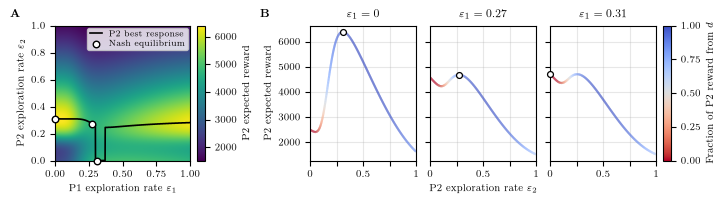

In [3]:
"""Figure 3: (A) player 2's payoff, best response, and the Nash equilibria at
d = 4, R = 2.1, and (B) player 2's payoff against its own rate at three rates of
player 1."""

import matplotlib.pyplot as plt
import numpy as np

from competitive_exploration.equilibria import best_response, classify_points, find_nash
from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    PNAS_WIDTHS,
    add_colored_curve,
    save_figure,
    use_paper_style,
)

use_paper_style(final_size=True)
data = np.load(DATA_DIR / "two_agent_payoffs.npz")
Z_d = data["Z_d"]
Z = data["Z_0"] + Z_d
eps_grid = data["eps_grid"]

# Player 1 never explores, explores at the symmetric Nash rate, or explores at the
# anti-coordination Nash rate.
symmetric, anti_coordination, _, _ = classify_points(find_nash(Z)[0])
columns = [0, symmetric[0][1], max(anti_coordination[0])]

# Panels placed in inches, so that all four share the same top and bottom edges.
HEIGHT, BOTTOM, TOP = 1.35, 0.36, 0.19
A_LEFT, B_LEFT = 0.45, 3.0
B_WIDTH, B_GAP = 1.06, 0.14
BAR_GAP, BAR = 0.07, 0.08
W, H = PNAS_WIDTHS["double"], BOTTOM + HEIGHT + TOP
fig = plt.figure(figsize=(W, H))


def place(left, width):
    return fig.add_axes([left / W, BOTTOM / H, width / W, HEIGHT / H])


for x, letter in [(0.0, "A"), (B_LEFT - 0.5, "B")]:
    y = (BOTTOM + HEIGHT + 0.085) / H
    fig.text(x / W, y, rf"\textbf{{{letter}}}", ha="left", va="baseline", fontsize=8)

# A
ax = place(A_LEFT, HEIGHT)
image = ax.imshow(Z, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="viridis")
cax = place(A_LEFT + HEIGHT + BAR_GAP, BAR)
fig.colorbar(image, cax=cax).set_label("P2 expected reward")
ax.plot(
    eps_grid,
    eps_grid[best_response(Z)],
    color="black",
    linewidth=1.2,
    clip_on=False,
    zorder=10,
    label="P2 best response",
)
i, j = np.array(find_nash(Z)[0]).T
ax.scatter(
    eps_grid[j],
    eps_grid[i],
    s=22,
    facecolors="white",
    edgecolors="black",
    linewidth=1,
    clip_on=False,
    zorder=11,
    label="Nash equilibrium",
)
ax.set_xlabel(r"P1 exploration rate $\varepsilon_1$")
ax.set_ylabel(r"P2 exploration rate $\varepsilon_2$")
ax.legend(
    loc="upper right",
    fontsize=6,
    borderpad=0.3,
    labelspacing=0.25,
    handlelength=1.5,
    borderaxespad=0.3,
)

# B
axes = [place(B_LEFT + k * (B_WIDTH + B_GAP), B_WIDTH) for k in range(3)]
y_range = Z[:, columns].max() - Z[:, columns].min()
for ax, j in zip(axes, columns):
    add_colored_curve(ax, eps_grid, Z[:, j], Z_d[:, j] / Z[:, j], linewidth=1.5)
    best = np.argmax(Z[:, j])
    ax.scatter(
        eps_grid[best],
        Z[best, j],
        s=18,
        facecolors="white",
        edgecolors="black",
        linewidth=0.9,
        zorder=5,
        clip_on=False,
    )
    ax.set_title(rf"$\varepsilon_1 = {eps_grid[j]:.2g}$")
    ax.set_xlim(0, 1)
    ax.set_ylim(Z[:, columns].min() - 0.05 * y_range, Z[:, columns].max() + 0.05 * y_range)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0", "", "0.5", "", "1"])
    ax.grid(True)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
axes[1].set_xlabel(r"P2 exploration rate $\varepsilon_2$")
axes[0].set_ylabel("P2 expected reward")
cax = place(B_LEFT + 3 * B_WIDTH + 2 * B_GAP + BAR_GAP, BAR)
fig.colorbar(
    plt.cm.ScalarMappable(plt.Normalize(0, 1), "coolwarm_r"),
    cax=cax,
    ticks=[0, 0.25, 0.5, 0.75, 1],
).set_label(r"Fraction of P2 reward from $d$")

save_figure(fig, "payoff_matrix_and_slices.pdf")

## Figure 4
`scripts/figures/four_regimes_payoff_and_localBR.py`

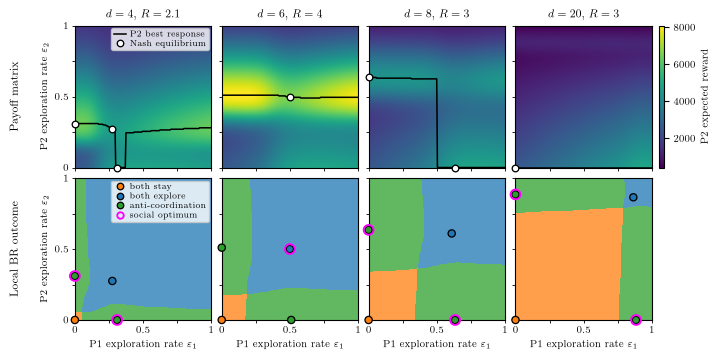

In [4]:
"""Figure 4: payoffs, Nash equilibria, and local best-response basins in four regimes."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from competitive_exploration.equilibria import best_response
from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    OUTCOME_CMAP,
    OUTCOME_LABELS,
    CM,
    PNAS_WIDTHS,
    SOCIAL_OPTIMUM_COLOR,
    add_row_label,
    plot_basins,
    save_figure,
    use_paper_style,
)

use_paper_style(final_size=True)
SCALE = 0.55  # marker sizes and line widths, relative to the defaults of plot_basins
data = np.load(DATA_DIR / "two_agent_local_br.npz")
eps_grid = data["eps_grid"]
Z_all = data["Z"]

# Printed at 0.99 \linewidth.
fig = plt.figure(figsize=(0.99 * PNAS_WIDTHS["double"], 8.67 * CM), layout="constrained")
grid = fig.add_gridspec(
    2, 5, width_ratios=[1, 1, 1, 1, 0.035], wspace=0, hspace=0
)
# Pads chosen to make the gaps between rows and between columns equal.
fig.get_layout_engine().set(w_pad=0.022, h_pad=0.01, wspace=0, hspace=0)
axes = np.array([[fig.add_subplot(grid[row, k]) for k in range(4)] for row in range(2)])

for k, (d, R) in enumerate(zip(data["d_values"], data["R_values"])):
    top, bottom = axes[:, k]

    image = top.imshow(
        Z_all[k],
        origin="lower",
        extent=[0, 1, 0, 1],
        aspect="auto",
        cmap="viridis",
        vmin=Z_all.min(),
        vmax=Z_all.max(),
    )
    top.plot(
        eps_grid,
        eps_grid[best_response(Z_all[k])],
        color="black",
        linewidth=2 * SCALE,
        zorder=10,
    )
    i, j = np.nonzero(data["nash"][k])
    top.scatter(
        eps_grid[j],
        eps_grid[i],
        s=75 * SCALE**2,
        facecolors="white",
        edgecolors="black",
        linewidths=1.7 * SCALE,
        zorder=11,
        clip_on=False,
    )
    top.set_title(rf"$d = {d}$, $R = {R:g}$")
    for ax in (top, bottom):
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0", "", "0.5", "", "1"])
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "", "0.5", "", "1"])
        ax.tick_params(length=2.5, width=0.6, pad=2)
    top.set_xticklabels([])

    plot_basins(
        bottom,
        eps_grid,
        data["codes"][k],
        data["endpoints"][k],
        data["social_optimum"][k],
        scale=SCALE,
    )
    bottom.set_xlabel(r"P1 exploration rate $\varepsilon_1$")

    if k == 0:
        top.set_ylabel(r"P2 exploration rate $\varepsilon_2$")
        bottom.set_ylabel(r"P2 exploration rate $\varepsilon_2$")
    else:
        top.set_yticklabels([])
        bottom.set_yticklabels([])

fig.colorbar(image, cax=fig.add_subplot(grid[0, 4])).set_label("P2 expected reward")
add_row_label(axes[0, 0], "Payoff matrix", x=-0.44)
add_row_label(axes[1, 0], "Local BR outcome", x=-0.44)


def marker(label, face, edge="black", width=1.7 * SCALE):
    return Line2D(
        [],
        [],
        marker="o",
        linestyle="none",
        markersize=8.5 * SCALE,
        markerfacecolor=face,
        markeredgecolor=edge,
        markeredgewidth=width,
        label=label,
    )


LEGEND_STYLE = dict(
    loc="upper right",
    fontsize=6,
    handlelength=1.5,
    handletextpad=0.4,
    borderpad=0.3,
    labelspacing=0.25,
    borderaxespad=0.3,
)
axes[0, 0].legend(
    handles=[
        Line2D([], [], color="black", linewidth=2 * SCALE, label="P2 best response"),
        marker("Nash equilibrium", "white"),
    ],
    **LEGEND_STYLE,
)
axes[1, 0].legend(
    handles=[marker(OUTCOME_LABELS[code], OUTCOME_CMAP(code)) for code in range(3)]
    + [marker("social optimum", "none", SOCIAL_OPTIMUM_COLOR, 2.4 * SCALE)],
    **LEGEND_STYLE,
)

save_figure(fig, "four_regimes_payoff_and_localBR.pdf")

## Figure 5
`scripts/figures/nash_social_dilemma_classification.py`

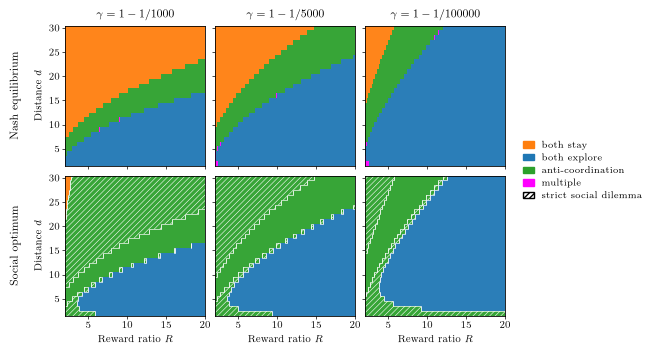

In [5]:
"""Figure 5: type of the Nash equilibria and of the socially optimal locally stable
point over reward ratio and distance, with strict social dilemmas hatched."""

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch, Rectangle

from competitive_exploration.equilibria import OTHER
from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    OUTCOME_CMAP,
    OUTCOME_LABELS,
    OUTCOME_NORM,
    PANEL_SIZE,
    add_row_label,
    centers_to_edges,
    place_panels,
    save_figure,
    use_paper_style,
)

use_paper_style(final_size=True)
# Distances d = 2-30 (Methods). At d = 1 every strict dilemma is a shortfall of at
# most 0.022% in collective payoff between neighboring near-symmetric equilibria on the grid.
D_MIN = 2
raw = np.load(DATA_DIR / "sweep_nash_social_dilemma_fine401.npz")
keep = raw["d_values"] >= D_MIN
data = {key: raw[key] for key in raw.files}
data["d_values"] = raw["d_values"][keep]
for key in ["nash_type", "social_optimum_type", "strict_dilemma"]:
    data[key] = raw[key][:, keep]
R_edges = centers_to_edges(data["R_values"])
d_edges = centers_to_edges(data["d_values"])
types = {key: data[key].copy() for key in ["nash_type", "social_optimum_type"]}
assert not (types["social_optimum_type"] == OTHER).any() and not (types["nash_type"] == OTHER).any()


def hatch_cells(ax, mask):
    """Hatch the cells where mask is True and outline the hatched region."""
    outline = []
    with mpl.rc_context({"hatch.linewidth": 0.4}):
        for a, r in np.argwhere(mask):
            x0, x1, y0, y1 = R_edges[r], R_edges[r + 1], d_edges[a], d_edges[a + 1]
            ax.add_patch(
                Rectangle(
                    (x0, y0),
                    x1 - x0,
                    y1 - y0,
                    facecolor="none",
                    edgecolor="white",
                    hatch="//////",
                    linewidth=0,
                    zorder=10,
                )
            )
            if r > 0 and not mask[a, r - 1]:
                outline.append([(x0, y0), (x0, y1)])
            if r < mask.shape[1] - 1 and not mask[a, r + 1]:
                outline.append([(x1, y0), (x1, y1)])
            if a > 0 and not mask[a - 1, r]:
                outline.append([(x0, y0), (x1, y0)])
            if a < mask.shape[0] - 1 and not mask[a + 1, r]:
                outline.append([(x0, y1), (x1, y1)])
    ax.add_collection(
        LineCollection(outline, colors="white", linewidths=0.6, zorder=11)
    )


# Square panels the size of those in Figure 4, with the legend on the right.
width, height, left, bottom, gap = 6.45, 3.45, 0.6, 0.33, 0.1
fig, axes = plt.subplots(
    2, len(data["T_values"]), figsize=(width, height), sharex=True, sharey=True
)
place_panels(fig, axes, PANEL_SIZE, left, bottom, wspace=gap, hspace=gap)
for t, T in enumerate(data["T_values"]):
    for row, key in enumerate(["nash_type", "social_optimum_type"]):
        axes[row, t].pcolormesh(
            R_edges,
            d_edges,
            types[key][t],
            cmap=OUTCOME_CMAP,
            norm=OUTCOME_NORM,
            alpha=0.95,
            antialiased=False,
            rasterized=True,
        )
    hatch_cells(axes[1, t], data["strict_dilemma"][t])
    axes[0, t].set_title(rf"$\gamma = 1 - 1/{T}$")
    axes[1, t].set_xlabel(r"Reward ratio $R$")

for ax in axes.ravel():
    ax.set_xticks([5, 10, 15, 20])
    ax.set_yticks([5, 10, 15, 20, 25, 30])
    ax.tick_params(length=2, width=0.5, pad=2)
    for spine in ax.spines.values():
        spine.set_zorder(30)
        spine.set_linewidth(0.6)
for row, label in enumerate(["Nash equilibrium", "Social optimum"]):
    axes[row, 0].set_ylabel(r"Distance $d$")
    add_row_label(axes[row, 0], label, x=-0.36)

present = np.union1d(types["nash_type"], types["social_optimum_type"])
fig.legend(
    handles=[
        Patch(color=OUTCOME_CMAP(code), label=OUTCOME_LABELS[code]) for code in present
    ]
    + [
        Patch(
            facecolor="white",
            edgecolor="black",
            hatch="//////",
            label="strict social dilemma",
        )
    ],
    loc="center left",
    bbox_to_anchor=(
        (left + 3 * PANEL_SIZE + 2 * gap + 0.1) / width,
        (bottom + PANEL_SIZE + gap / 2) / height,
    ),
    handlelength=1.2,
    frameon=False,
)

save_figure(fig, "nash_social_dilemma_classification.pdf")

## Figure 6
`scripts/figures/signaling_dilemma_summary_sampled_refined.py`

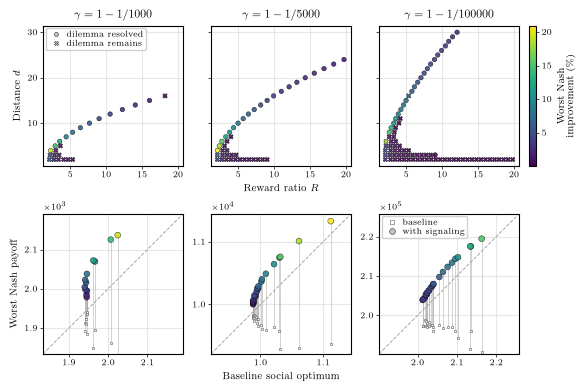

In [6]:
"""Figure 6: which strict dilemmas with both agents exploring at the worst Nash
equilibrium are removed by signaling, and by how much the worst Nash payoff rises.

For legibility the top row shows every seventh candidate reward ratio at each
distance; the bottom row shows the removed dilemmas among those."""

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

from competitive_exploration.paths import DATA_DIR
from competitive_exploration.plotting import (
    PANEL_SIZE,
    place_panels,
    save_figure,
    use_paper_style,
)

use_paper_style(final_size=True)
# Bottom-row axis limits, by T, equal on both axes. Two removed dilemmas lie partly
# outside them (SI Section S8.2): limits fitted to every point would stretch the
# T = 100000 panel to 1.9e5-8.8e5 because of the dilemma at d = 3, R = 9.03.
LIMITS = {1000: (1834, 2191), 5000: (9211, 11445), 100000: (190217, 225800)}
# Tick and legend labels at the smallest PNAS size, and short ticks, to save space.
TICK = 6
plt.rcParams.update(
    {
        "xtick.labelsize": TICK,
        "ytick.labelsize": TICK,
        "legend.fontsize": TICK,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.major.pad": 2,
        "ytick.major.pad": 2,
    }
)
base = np.load(DATA_DIR / "sweep_nash_social_dilemma_fine401.npz")
signaling = np.load(DATA_DIR / "signaling_fine401.npz")
T_values, d_values, R_values = base["T_values"], base["d_values"], base["R_values"]

SOLVED = 0
STRIDE = 7
worst = signaling["worst_nash_payoff"]
improvement = 100 * (worst - base["worst_nash_payoff"]) / base["worst_nash_payoff"]

# Every STRIDE-th candidate R at each (gamma, d), among candidates at which a Nash
# equilibrium remains after signaling (SI Section S8.2).
shown = np.zeros_like(signaling["candidate"])
for t, a in np.ndindex(shown.shape[:2]):
    r = np.flatnonzero(signaling["candidate"][t, a] & np.isfinite(worst[t, a]))
    shown[t, a, r[::STRIDE]] = True
solved = shown & (signaling["status"] == SOLVED)
remains = shown & ~solved
norm = plt.Normalize(np.nanmin(improvement[shown]), np.nanmax(improvement[shown]))


# Square panels the size of those in Figure 4 (and Figure 5).
width, height, left, bottom, wspace, hspace = 5.73, 3.82, 0.36, 0.32, 0.28, 0.48
fig, axes = plt.subplots(2, len(T_values), figsize=(width, height))
place_panels(fig, axes, PANEL_SIZE, left, bottom, wspace, hspace)
for ax in axes[0, 1:]:
    ax.sharex(axes[0, 0])
    ax.sharey(axes[0, 0])
    ax.tick_params(labelleft=False)

for t, T in enumerate(T_values):
    ax = axes[0, t]
    for mask, marker in [(solved[t], "o"), (remains[t], "X")]:
        a, r = np.nonzero(mask)
        order = np.argsort(improvement[t, a, r])
        ax.scatter(
            R_values[r[order]],
            d_values[a[order]],
            c=improvement[t, a, r][order],
            cmap="viridis",
            norm=norm,
            marker=marker,
            s=11,
            edgecolor="black",
            linewidth=0.3,
            alpha=0.9,
            zorder=2,
        )
    ax.set_title(rf"$\gamma = 1 - 1/{T}$")
    ax.set_yticks([10, 20, 30])
    ax.grid(True)

    ax = axes[1, t]
    mask = solved[t] & np.isfinite(worst[t])
    order = np.argsort(improvement[t][mask])
    x = base["best_local_payoff"][t][mask][order]
    before = base["worst_nash_payoff"][t][mask][order]
    after = worst[t][mask][order]
    ax.vlines(x, before, after, color="0.65", linewidth=0.5, alpha=0.7, zorder=1)
    ax.scatter(
        x,
        before,
        marker="s",
        s=4,
        facecolor="white",
        edgecolor="0.35",
        linewidth=0.4,
        zorder=2,
    )
    ax.scatter(
        x,
        after,
        c=improvement[t][mask][order],
        cmap="viridis",
        norm=norm,
        s=18,
        edgecolor="black",
        linewidth=0.3,
        alpha=0.9,
        zorder=3,
    )
    limits = LIMITS[int(T)]
    ax.plot(limits, limits, "--", color="0.65", linewidth=0.7, zorder=0)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.ticklabel_format(style="sci", scilimits=(0, 0), useMathText=True)
    step = 10 ** np.floor(np.log10(limits[1])) / 10
    ax.xaxis.set_major_locator(MultipleLocator(step))
    ax.yaxis.set_major_locator(MultipleLocator(step))
    # The axes share one scale, so the power of ten is shown once, above the y-axis.
    ax.xaxis.get_offset_text().set_visible(False)
    ax.grid(True)

axes[0, 1].set_xlabel(r"Reward ratio $R$")
axes[1, 1].set_xlabel("Baseline social optimum")
axes[0, 0].set_ylabel(r"Distance $d$")
axes[1, 0].set_ylabel("Worst Nash payoff")


def marker(label, shape, face="0.75", edge="black", width=0.3, size=3):
    return Line2D(
        [],
        [],
        marker=shape,
        linestyle="none",
        markerfacecolor=face,
        markeredgecolor=edge,
        markeredgewidth=width,
        markersize=size,
        label=label,
    )


LEGEND_STYLE = dict(
    loc="upper left",
    handletextpad=0.2,
    borderpad=0.3,
    labelspacing=0.2,
    borderaxespad=0.3,
    framealpha=0.9,
)
axes[0, 0].legend(
    handles=[marker("dilemma resolved", "o"), marker("dilemma remains", "X")],
    **LEGEND_STYLE,
)
# In the last panel, whose upper left is empty; elsewhere it would cover data.
axes[1, 2].legend(
    handles=[
        marker("baseline", "s", face="white", edge="0.35", width=0.4, size=2.5),
        marker("with signaling", "o", size=4.2),
    ],
    **LEGEND_STYLE,
)

colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm, "viridis"),
    cax=fig.add_axes(
        [
            (left + 3 * PANEL_SIZE + 2 * wspace + 0.1) / width,
            (bottom + PANEL_SIZE + hspace) / height,
            0.07 / width,
            PANEL_SIZE / height,
        ]
    ),
)
colorbar.set_label("Worst Nash\nimprovement (\\%)", labelpad=4)

save_figure(fig, "signaling_dilemma_summary_sampled_refined.pdf")